# PathSnap · Team 111 — Data processing
**Deliverable: source code used to read, inspect, clean and preprocess the raw dataset.**

| Step | What | Output |
|---|---|---|
| 1 | **Read** the raw files | one trip loaded as tables |
| 2 | **Inspect** the whole dataset | inventory table + plots |
| 3 | **Inspect** data quality | quality report, gaps, route breaks |
| 4 | **Clean** | cleaning function + test |
| 5 | **Preprocess:** project to metres | per-trip projection + validation |
| 6 | **Preprocess:** road-network geometry | arc length, bearing, two-way flag, spatial index |
| 7 | **Preprocess:** labels (route → GPS point) | one reference arc per GPS point |
| 8 | **Preprocess:** candidate road arcs | candidates + candidate miss rate |
| 9 | **Save** processed data | files in `data/processed/` and `results/` |

Partitions used: **train** (80 trips) and **student_test** (10 trips). **evaluator_test is never read.**

**Run:** Runtime/Kernel → *Run all*. Locally it finds `data/raw/`; in **Google Colab** it asks you to upload
`Student_folder.zip` (the dataset zip) the first time.

## Step 0 — Setup

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

# ---- find the raw data: works locally (repo) and in Google Colab ---------------------
import zipfile
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")


def find_raw(start_dirs):
    """Return the first folder that contains both 'train' and 'student_test'."""
    for start in start_dirs:
        for d, subdirs, _ in os.walk(start):
            if "train" in subdirs and "student_test" in subdirs:
                return d
            if d.count(os.sep) - start.count(os.sep) > 3:   # don't search too deep
                subdirs[:] = []
    return None


IN_COLAB = os.path.isdir("/content")
search = [os.path.join(ROOT, "data", "raw"), ROOT] + (["/content"] if IN_COLAB else [])
RAW = find_raw([d for d in search if os.path.isdir(d)])
if RAW is None and IN_COLAB:
    from google.colab import files       # Colab: upload the dataset zip (Student_folder.zip)
    print("Dataset not found -> choose Student_folder.zip")
    for name in files.upload():
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall("/content/")
    RAW = find_raw(["/content"])
assert RAW is not None, "Dataset not found: put the 'train' and 'student_test' folders in data/raw/ (or upload Student_folder.zip in Colab)"
if IN_COLAB:
    ROOT = "/content"
OUT = os.path.join(ROOT, "data", "processed", "dp"); os.makedirs(OUT, exist_ok=True)
RES = os.path.join(ROOT, "results"); os.makedirs(RES, exist_ok=True)
PARTS = ["train", "student_test"]
R = 6371008.8  # mean Earth radius in metres
pd.set_option("display.width", 160)
print("raw data folder:", RAW)
print({p: len(os.listdir(os.path.join(RAW, p))) for p in PARTS})

ModuleNotFoundError: No module named 'numpy'

## Step 1 — Read the raw files
Every trip is a folder `<partition>/<trip_id>/` with four whitespace-separated files **without headers**:

| File | Columns | Meaning |
|---|---|---|
| `.track` | lon, lat, t | GPS observations, t in seconds |
| `.nodes` | lon, lat | road-network nodes, row number = node id |
| `.arcs` | from_node, to_node | directed road segments, row number = arc id |
| `.route` | arc_id | reference route: arcs driven, in order |

In [ ]:
def list_trips(part):
    return sorted(os.listdir(os.path.join(RAW, part)))


def read_trip(part, tid):
    d = os.path.join(RAW, part, tid)
    track = pd.read_csv(os.path.join(d, f"{tid}.track"), sep=r"\s+", header=None, names=["lon", "lat", "t"])
    nodes = pd.read_csv(os.path.join(d, f"{tid}.nodes"), sep=r"\s+", header=None, names=["lon", "lat"])
    arcs = pd.read_csv(os.path.join(d, f"{tid}.arcs"), sep=r"\s+", header=None, names=["from_node", "to_node"])
    route = pd.read_csv(os.path.join(d, f"{tid}.route"), sep=r"\s+", header=None, names=["arc_id"])
    return track, nodes, arcs, route


print({p: len(list_trips(p)) for p in PARTS})
track, nodes, arcs, route = read_trip("student_test", "00000076")
print(f"trip 00000076: {len(track)} GPS rows, {len(nodes)} nodes, {len(arcs)} arcs, {len(route)} route arcs")
track.head()

{'train': 80, 'student_test': 10}
trip 00000076: 1486 GPS rows, 26635 nodes, 56027 arcs, 374 route arcs


,lon,lat,t
0,44.007284,56.327700,1.0
1,44.007379,56.327709,4.0
2,44.007389,56.327798,5.0
3,44.007348,56.327821,16.0
4,44.007318,56.327885,17.0


In [ ]:
print(track.dtypes, "\n"); print(arcs.head(3), "\n"); print(route.head(3))

lon    float64
lat    float64
t      float64
dtype: object 

   from_node  to_node
0          0    22510
1          1    22746
2          1    22629 

   arc_id
0   46579
1   21523
2   15389


## Step 2 — Inspect the whole dataset (inventory)

In [ ]:
rows = []
for part in PARTS:
    for tid in list_trips(part):
        tr, nd, ar, rt = read_trip(part, tid)
        dt = np.diff(tr.t.values)
        lat0 = np.radians(tr.lat.mean())
        rows.append(dict(partition=part, trip=tid, gps_points=len(tr), nodes=len(nd), arcs=len(ar), route_arcs=len(rt),
                         duration_min=(tr.t.iloc[-1] - tr.t.iloc[0]) / 60,
                         pct_1s_steps=100 * (dt == 1).mean(), gaps_over_5s=int((dt > 5).sum()), max_gap_s=dt.max(),
                         extent_km=max(np.radians(np.ptp(tr.lon)) * R * np.cos(lat0), np.radians(np.ptp(tr.lat)) * R) / 1000,
                         lon_center=tr.lon.mean(), lat_center=tr.lat.mean()))
inv = pd.DataFrame(rows)
inv.to_csv(os.path.join(RES, "dp_inventory.csv"), index=False)
inv.groupby("partition").agg(trips=("trip", "size"), gps_points=("gps_points", "sum"),
                             median_points=("gps_points", "median"), median_nodes=("nodes", "median"),
                             median_arcs=("arcs", "median"), median_duration_min=("duration_min", "median"),
                             median_extent_km=("extent_km", "median")).round(1)

,trips,gps_points,median_points,median_nodes,median_arcs,median_duration_min,median_extent_km
partition,,,,,,,
student_test,10,19160,1420.0,6596.5,13145.0,30.2,6.4
train,80,208417,1529.0,9608.0,19526.5,28.5,8.6


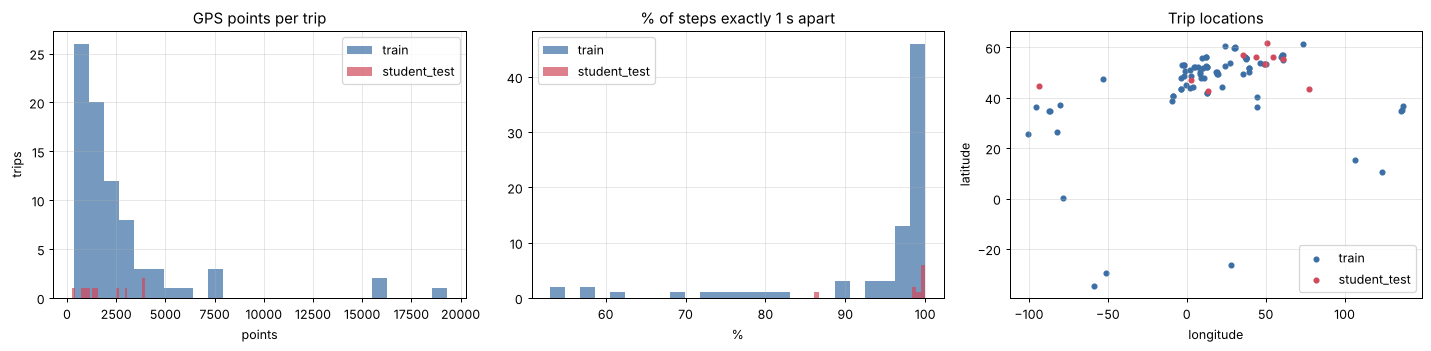

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for part, c in [("train", "#3b6ea5"), ("student_test", "#d1495b")]:
    s = inv[inv.partition == part]
    ax[0].hist(s.gps_points, bins=25, alpha=.7, color=c, label=part)
    ax[1].hist(s.pct_1s_steps, bins=25, alpha=.7, color=c, label=part)
    ax[2].scatter(s.lon_center, s.lat_center, color=c, s=15, label=part)
ax[0].set(title="GPS points per trip", xlabel="points", ylabel="trips")
ax[1].set(title="% of steps exactly 1 s apart", xlabel="%")
ax[2].set(title="Trip locations", xlabel="longitude", ylabel="latitude")
for a in ax:
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Observations:** 90 trips, 227,577 GPS points, sampled at ~1 Hz. Trips are spread over 5 continents,
so distances must be computed in a local metric frame per trip (Step 5).

## Step 3 — Inspect data quality

In [ ]:
q = []
for part in PARTS:
    for tid in list_trips(part):
        tr, nd, ar, rt = read_trip(part, tid)
        r = rt.arc_id.values
        dt = np.diff(tr.t.values)
        q.append(dict(partition=part, trip=tid,
                      missing_values=int(tr.isna().sum().sum() + nd.isna().sum().sum() + ar.isna().sum().sum()),
                      invalid_coords=int(((tr.lon.abs() > 180) | (tr.lat.abs() > 90)).sum()),
                      non_increasing_t=int((dt <= 0).sum()),
                      repeated_positions=int(((tr.lon.diff() == 0) & (tr.lat.diff() == 0)).sum()),
                      arcs_point_to_valid_nodes=bool(ar.values.min() >= 0 and ar.values.max() < len(nd)),
                      route_points_to_valid_arcs=bool(r.min() >= 0 and r.max() < len(ar)),
                      route_breaks=int((ar.to_node.values[r[:-1]] != ar.from_node.values[r[1:]]).sum()),
                      gaps_over_60s=int((dt > 60).sum())))
quality = pd.DataFrame(q)
quality.to_csv(os.path.join(RES, "dp_quality_report.csv"), index=False)
quality.groupby("partition")[["missing_values", "invalid_coords", "non_increasing_t", "repeated_positions",
                              "route_breaks", "gaps_over_60s"]].sum()

,missing_values,invalid_coords,non_increasing_t,repeated_positions,route_breaks,gaps_over_60s
partition,,,,,,
student_test,0,0,0,0,1,1
train,0,0,0,6,13,69


In [ ]:
print("all arcs point to valid nodes:", quality.arcs_point_to_valid_nodes.all())
print("all route arcs exist:", quality.route_points_to_valid_arcs.all())
print("trips with a broken reference route:", sorted(quality[quality.route_breaks > 0].trip))
inv.sort_values("max_gap_s", ascending=False)[["partition", "trip", "gps_points", "max_gap_s"]].head(5).assign(
    max_gap_h=lambda d: (d.max_gap_s / 3600).round(1))

all arcs point to valid nodes: True
all route arcs exist: True
trips with a broken reference route: ['00000002', '00000019', '00000033', '00000041', '00000042', '00000069', '00000075', '00000076', '00000080', '00000086', '00000089']


,partition,trip,gps_points,max_gap_s,max_gap_h
72,train,00000090,536,153064.0,42.5
61,train,00000078,2909,52810.0,14.7
55,train,00000069,2067,2658.0,0.7
16,train,00000021,15783,2161.0,0.6
8,train,00000011,2828,909.0,0.3


**Findings:**
- No missing values, no impossible coordinates, timestamps always increase, all ids valid.
- Some long time gaps (up to ~42 h in train 90): the car was parked — the position hardly moves across the gap. **Keep the trips whole.**
- 11 trips have a **broken reference route** (two consecutive route arcs that don't connect): a limitation of the reference, kept and noted.
- Repeated identical positions = vehicle standing still: real observations, **kept**.

## Step 4 — Clean
The raw train/student_test files need no fixes, but the evaluator files might. The cleaning function removes:
1. rows with missing values, 2. impossible coordinates, 3. repeated or backwards timestamps (keeps the first).

In [ ]:
def clean_track(tr):
    ok = tr[["lon", "lat", "t"]].notna().all(axis=1) & (tr.lon.abs() <= 180) & (tr.lat.abs() <= 90)
    tr = tr[ok]
    increasing = tr.t > tr.t.cummax().shift(fill_value=-np.inf)
    return tr[increasing].reset_index(drop=True)


# test on a deliberately corrupted copy
bad = track.copy()
bad.loc[10, "lon"] = np.nan          # missing value
bad.loc[20, "lon"] = 200.0           # impossible longitude
bad.loc[30, "t"] = bad.loc[29, "t"]  # repeated timestamp
print("corrupted:", len(bad), "-> cleaned:", len(clean_track(bad)), "(3 bad rows removed)")

removed = sum(len(read_trip(p, t)[0]) - len(clean_track(read_trip(p, t)[0])) for p in PARTS for t in list_trips(p))
print("rows removed from the real train + student_test data:", removed)

corrupted: 1486 -> cleaned: 1483 (3 bad rows removed)
rows removed from the real train + student_test data: 0


## Step 5 — Preprocess: project to metres
Longitude/latitude are angles: 1° of longitude is ~111 km at the equator but ~55 km at 60°N.
Each trip gets its own **local equirectangular projection** centred on its mean GPS position:
`x = R·Δlon·cos(lat0)`, `y = R·Δlat`. Checked against the exact great-circle (haversine) distance.

In [ ]:
def make_projection(track):
    lon0, lat0 = track.lon.mean(), track.lat.mean()
    def project(lon, lat):
        return np.column_stack([np.radians(lon - lon0) * R * np.cos(np.radians(lat0)), np.radians(lat - lat0) * R])
    return project


def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


rng = np.random.RandomState(111)
errs = []
for part in PARTS:
    for tid in list_trips(part):
        tr = clean_track(read_trip(part, tid)[0]); proj = make_projection(tr); xy = proj(tr.lon.values, tr.lat.values)
        i, j = rng.randint(0, len(tr), 300), rng.randint(0, len(tr), 300)
        true = haversine(tr.lon.values[i], tr.lat.values[i], tr.lon.values[j], tr.lat.values[j]); m = true > 50
        errs.append(100 * np.max(np.abs(np.hypot(*(xy[i] - xy[j]).T)[m] - true[m]) / true[m]))
print(f"projection error vs haversine over 90 trips: median of max {np.median(errs):.3f}%, worst {np.max(errs):.3f}%")

projection error vs haversine over 90 trips: median of max 0.043%, worst 0.531%


## Step 6 — Preprocess: road-network geometry
Arcs are straight segments between two nodes. For each arc: length, bearing (direction), and whether the
opposite-direction twin exists (two-way road). A KD-tree over points every 10 m along every arc lets us
find nearby arcs for any GPS point quickly.

In [ ]:
class Network:
    def __init__(self, nodes, arcs, project, step=10.0):
        self.arcs = arcs[["from_node", "to_node"]].values
        self.node_xy = project(nodes.lon.values, nodes.lat.values)
        self.A = self.node_xy[self.arcs[:, 0]]; self.AB = self.node_xy[self.arcs[:, 1]] - self.A
        self.length = np.hypot(*self.AB.T)
        self.bearing = (np.degrees(np.arctan2(self.AB[:, 0], self.AB[:, 1])) + 360) % 360
        pairs = set(map(tuple, self.arcs.tolist()))
        self.two_way = np.array([(v, u) in pairs for u, v in self.arcs.tolist()])
        n = np.maximum(2, np.ceil(self.length / step).astype(int) + 1)
        self.sample_arc = np.repeat(np.arange(len(self.arcs)), n)
        frac = np.concatenate([np.linspace(0, 1, k) for k in n])
        self.tree = cKDTree(self.A[self.sample_arc] + frac[:, None] * self.AB[self.sample_arc])
        self.step = step

    def distance(self, p, arc_ids):
        """Perpendicular distance (m) and position along the arc (0..1) for points p and arcs arc_ids."""
        a, ab = self.A[arc_ids], self.AB[arc_ids]
        t = np.clip(((p - a) * ab).sum(1) / np.maximum((ab ** 2).sum(1), 1e-9), 0, 1)
        return np.hypot(*(p - (a + t[:, None] * ab)).T), t


tr = clean_track(track); proj = make_projection(tr)
net = Network(nodes, arcs, proj)
print(f"trip 76: median arc {np.median(net.length):.1f} m, {100 * net.two_way.mean():.0f}% two-way arcs, "
      f"{len(net.sample_arc):,} indexed points")

trip 76: median arc 21.3 m, 96% two-way arcs, 263,063 indexed points


## Step 7 — Preprocess: labels (reference route → one arc per GPS point)
The `.route` file lists the arcs driven **in order** but doesn't say which GPS point is on which arc.
**Rule:** give each point a position in the route list so that positions never go backwards and the
total point-to-arc distance is as small as possible. Dynamic programming:

`D[i, j] = dist(point i, route[j]) + min over k ≤ j of D[i−1, k]`, then trace back the best path.

In [ ]:
def align_route(xy, route_arcs, net):
    N, M = len(xy), len(route_arcs)
    cost = lambda p: net.distance(np.repeat(p[None], M, 0), route_arcs)[0]
    back = np.zeros((N, M), dtype=np.int32)
    prev = cost(xy[0])
    for i in range(1, N):
        best = np.minimum.accumulate(prev)                            # best score at any position <= j
        new_min = np.concatenate([[True], prev[1:] < best[:-1]])
        back[i] = np.maximum.accumulate(np.where(new_min, np.arange(M), 0))
        prev = best + cost(xy[i])
    pos = np.zeros(N, dtype=int); j = int(prev.argmin())
    for i in range(N - 1, -1, -1):
        pos[i] = j; j = back[i, j]
    label = route_arcs[pos]
    return label, net.distance(xy, label)[0]


xy = proj(tr.lon.values, tr.lat.values)
label, label_dist = align_route(xy, route.arc_id.values, net)
print(f"trip 76: median distance GPS -> its label arc {np.median(label_dist):.1f} m, 95th percentile {np.percentile(label_dist, 95):.1f} m")

trip 76: median distance GPS -> its label arc 6.8 m, 95th percentile 18.7 m


## Step 8 — Preprocess: candidate road arcs
For each GPS point: all arcs within **50 m**, nearest **8** kept; if none within 50 m, the **3 nearest** arcs
(so every point always has candidates). **Candidate miss rate** = share of points whose label arc is not a candidate.

In [ ]:
def candidates(xy, net, radius=50.0, k=8, k_fallback=3):
    out = []
    for i, hits in enumerate(net.tree.query_ball_point(xy, radius + net.step)):
        ids = np.unique(net.sample_arc[hits]) if hits else np.zeros(0, int)
        if len(ids):
            d, _ = net.distance(np.repeat(xy[i][None], len(ids), 0), ids)
            ids = ids[d <= radius][np.argsort(d[d <= radius])][:k]
        if len(ids) == 0:
            _, nn = net.tree.query(xy[i], k=200)
            ids = np.array(list(dict.fromkeys(net.sample_arc[nn]))[:k_fallback])
        out.append(ids)
    return out


c = candidates(xy, net)
print(f"trip 76: {np.mean([len(x) for x in c]):.2f} candidates per point, "
      f"miss rate {100 * np.mean([label[i] not in c[i] for i in range(len(c))]):.2f}%")

trip 76: 7.49 candidates per point, miss rate 0.74%


## Step 9 — Run Steps 4–8 on every trip and save
Saved per partition: a **points table** (one row per GPS point: x, y, t, label, label distance) and a
**candidates table** (one row per point × candidate arc, with distance and `is_label`).
Trips whose GPS is mostly > 100 m from its reference route are flagged as **unreliable labels**.

In [ ]:
summary, t0 = [], time.time()
for part in PARTS:
    pts_all, cand_all = [], []
    for tid in list_trips(part):
        tr0, nd, ar, rt = read_trip(part, tid)
        tr = clean_track(tr0); proj = make_projection(tr); net = Network(nd, ar, proj)
        xy = proj(tr.lon.values, tr.lat.values)
        label, ldist = align_route(xy, rt.arc_id.values, net)
        cands = candidates(xy, net)
        pi = np.repeat(np.arange(len(xy)), [len(x) for x in cands]); ca = np.concatenate(cands)
        d, tpos = net.distance(xy[pi], ca)
        pts_all.append(pd.DataFrame(dict(trip=tid, pt=np.arange(len(xy)), lon=tr.lon, lat=tr.lat, x=xy[:, 0], y=xy[:, 1],
                                         t=tr.t, label_arc=label, label_dist_m=ldist)))
        cand_all.append(pd.DataFrame(dict(trip=tid, pt=pi, arc=ca, dist_m=d, t_proj=tpos, arc_len_m=net.length[ca],
                                          arc_bearing=net.bearing[ca], two_way=net.two_way[ca], is_label=(ca == label[pi]))))
        summary.append(dict(partition=part, trip=tid, points=len(xy), rows_removed=len(tr0) - len(tr),
                            label_dist_median_m=np.median(ldist), pct_label_over_100m=100 * (ldist > 100).mean(),
                            mean_candidates=len(ca) / len(xy),
                            candidate_miss_rate_pct=100 * (1 - pd.Series(ca == label[pi]).groupby(pi).max().mean())))
    pd.concat(pts_all).to_pickle(os.path.join(OUT, f"{part}_points.pkl"))
    pd.concat(cand_all).to_pickle(os.path.join(OUT, f"{part}_candidates.pkl"))
summ = pd.DataFrame(summary)
summ["unreliable_labels"] = summ.pct_label_over_100m > 30
summ.to_csv(os.path.join(RES, "dp_processing_summary.csv"), index=False)
print(f"processed 90 trips in {time.time() - t0:.0f} s -> {OUT}")
summ.groupby("partition").agg(trips=("trip", "size"), points=("points", "sum"), rows_removed=("rows_removed", "sum"),
                              median_label_dist_m=("label_dist_median_m", "median"),
                              mean_candidates=("mean_candidates", "mean"),
                              mean_miss_rate_pct=("candidate_miss_rate_pct", "mean"),
                              unreliable_label_trips=("unreliable_labels", "sum")).round(2)

processed 90 trips in 43 s -> /home/claude/pathsnap-team111/data/processed/dp


,trips,points,rows_removed,median_label_dist_m,mean_candidates,mean_miss_rate_pct,unreliable_label_trips
partition,,,,,,,
student_test,10,19160,0,4.74,6.11,0.42,0
train,80,208417,0,4.63,6.19,3.09,2


In [ ]:
summ[summ.unreliable_labels][["partition", "trip", "points", "label_dist_median_m", "pct_label_over_100m", "candidate_miss_rate_pct"]].round(1)

,partition,trip,points,label_dist_median_m,pct_label_over_100m,candidate_miss_rate_pct
26,train,00000033,5844,122.4,51.0,67.1
44,train,00000054,19313,140.0,85.2,89.6


## Summary
- **Read:** 4 headerless files per trip, 90 trips (train + student_test).
- **Inspect:** no missing/invalid values; 1 Hz sampling; long parking gaps; 11 trips with broken reference routes; trips on 5 continents.
- **Clean:** `clean_track()` removes missing, impossible and non-increasing rows (0 rows needed removal here; tested on corrupted data).
- **Preprocess:** per-trip projection to metres (validated against haversine), road geometry + spatial index,
  per-point labels by monotonic route alignment, candidates within 50 m (≤ 8, fallback 3).
- **Flagged:** trips 33 and 54 have unreliable reference labels and are excluded from model training.
- **Saved:** `data/processed/dp/*_points.pkl`, `*_candidates.pkl`, and `results/dp_*.csv`.

Next stage: feature engineering on the candidates table (`notebooks/02_data_processing_feature_engineering.ipynb`).